# 03 — Exploratory Data Analysis

## Purpose and scope

This notebook explores the UCI Online Retail transaction data to understand purchasing patterns, geographic concentration, product behaviour, customer-level variation and cancellation activity.

The analysis is descriptive: it helps identify patterns and informs the preprocessing decisions used in the customer-segmentation workflow. It does not establish causal relationships.

**Analytical view:** Purchase-based analyses use a preliminary customer-identified paid-purchase view. It excludes records without a CustomerID, cancellation invoices, non-positive quantities and non-positive unit prices, and removes exact duplicate rows. It is not yet the final merchandise-only modelling dataset.

**Important:** The original raw dataset remains unchanged. Formal transaction-level cleaning and customer-feature engineering are documented in Notebook 04.

## 1. Libraries, paths and data loading

Load the original dataset and construct the preliminary paid-purchase view used for the descriptive analyses. Output folders are created for the figures and summary tables generated by this notebook.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.data_loading import load_online_retail
from src.eda import customer_identified_paid_view
FIG = PROJECT_ROOT/'reports/phase_2/figures'
TAB = PROJECT_ROOT/'reports/phase_2/tables'
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
df = load_online_retail()
paid = customer_identified_paid_view(df, remove_exact_duplicates=True)
print('Raw rows:', len(df))
print('Customer-identified paid rows after exact de-duplication:', len(paid))
print('Customers:', paid['CustomerID'].nunique())
print('Distinct paid invoices:', paid['InvoiceNo'].nunique())
print('Gross line value (£):', round(paid['LineValue'].sum(), 2))

Raw rows: 541909
Customer-identified paid rows after exact de-duplication: 392692
Customers: 4338
Distinct paid invoices: 18532
Gross line value (£): 8887208.89


### Initial dataset snapshot

The raw dataset contains **541,909 transaction rows**. The preliminary customer-identified paid-purchase view contains **392,692 rows**, representing **4,338 identified customers** and **18,532 distinct invoices**, with gross line value of **£8,887,208.89**.

These figures describe the preliminary EDA view, not the final merchandise-only dataset. The difference is important because subsequent preprocessing excludes special transaction codes and applies the project's final analytical rules.

## 2. StockCode investigation and special transaction codes

StockCode is not exclusively numeric. Many alphanumeric values are valid product identifiers, so the presence of letters alone is not a reason to remove a record. This section distinguishes merchandise identifiers from non-merchandise transaction codes.

In [2]:
# Investigate non-standard stock codes

print("STOCK CODE DISTRIBUTION")
print("-" * 45)

# Most frequently occurring stock codes
display(
    df["StockCode"]
    .value_counts()
    .head(25)
    .to_frame("Record_Count")
)

# Identify stock codes containing alphabetic characters
stock_code_text = df["StockCode"].astype(str).str.strip()

non_numeric_codes = df[
    stock_code_text.str.contains(r"[A-Za-z]", regex=True, na=False)
].copy()

print("\nRecords with alphabetic StockCodes:",
      len(non_numeric_codes))

print("\nMost frequent non-standard StockCodes:")

display(
    non_numeric_codes.groupby("StockCode")
    .agg(
        Record_Count=("InvoiceNo", "size"),
        Description=("Description", "first"),
        Mean_UnitPrice=("UnitPrice", "mean"),
        Customer_Count=("CustomerID", "nunique")
    )
    .sort_values("Record_Count", ascending=False)
    .head(30)
)

STOCK CODE DISTRIBUTION
---------------------------------------------


,Record_Count
StockCode,
85123A,2313
22423,2203
85099B,2159
47566,1727
20725,1639
84879,1502
22720,1477
22197,1476
21212,1385



Records with alphabetic StockCodes: 54873

Most frequent non-standard StockCodes:


,Record_Count,Description,Mean_UnitPrice,Customer_Count
StockCode,,,,
85123A,2313,WHITE HANGING HEART T-LIGHT HOLDER,3.103238,858
85099B,2159,JUMBO BAG RED RETROSPOT,2.470264,636
POST,1256,POSTAGE,36.933495,379
85099C,960,JUMBO BAG BAROQUE BLACK WHITE,2.593406,306
82494L,943,WOODEN FRAME ANTIQUE WHITE,3.234984,392
85099F,842,JUMBO BAG STRAWBERRY,2.357530,317
DOT,710,DOTCOM POSTAGE,290.495859,1
M,571,Manual,375.566392,276
84970S,546,HANGING HEART ZINC T-LIGHT HOLDER,1.135989,271


### Interpretation: StockCode distribution

The most frequent StockCodes include alphanumeric identifiers such as `85123A` and `85099B`, which correspond to ordinary merchandise. The raw-data audit also identifies special codes such as `POST` (postage), `DOT` (dotcom postage) and `M` (manual entries).

**Preprocessing implication:** Do not remove all alphabetic StockCodes. Identify and handle known non-merchandise codes separately, while retaining valid alphanumeric product identifiers.

In [3]:
# Audit the existing paid-purchase analytical view

print("ORIGINAL DATASET")
print("Rows:", len(df))
print("Unique customers:", df["CustomerID"].nunique())

print("\nPAID-PURCHASE VIEW")
print("Rows:", len(paid))
print("Unique customers:", paid["CustomerID"].nunique())
print("Unique invoices:", paid["InvoiceNo"].nunique())
print("Unique products:", paid["StockCode"].nunique())

print("\nFILTERING IMPACT")
print("Rows excluded:", len(df) - len(paid))
print("Percentage retained:",
      round(len(paid) / len(df) * 100, 2), "%")

print("\nNON-STANDARD STOCK CODES IN PAID VIEW")

non_standard_codes = paid[
    paid["StockCode"].astype(str).str.contains(
        r"[A-Za-z]", regex=True, na=False
    )
]

display(
    non_standard_codes.groupby("StockCode")
    .agg(
        Record_Count=("InvoiceNo", "size"),
        Customer_Count=("CustomerID", "nunique"),
        Description=("Description", "first"),
        Total_Quantity=("Quantity", "sum"),
        Total_Value=("LineValue", "sum")
    )
    .sort_values("Record_Count", ascending=False)
    .head(25)
)

ORIGINAL DATASET
Rows: 541909
Unique customers: 4372

PAID-PURCHASE VIEW
Rows: 392692
Unique customers: 4338
Unique invoices: 18532
Unique products: 3665

FILTERING IMPACT
Rows excluded: 149217
Percentage retained: 72.46 %

NON-STANDARD STOCK CODES IN PAID VIEW


,Record_Count,Customer_Count,Description,Total_Quantity,Total_Value
StockCode,,,,,
85123A,2023,856,WHITE HANGING HEART T-LIGHT HOLDER,36763,100547.45
85099B,1615,635,JUMBO BAG RED RETROSPOT,46078,85040.54
POST,1099,331,POSTAGE,3120,77803.96
82494L,816,392,WOODEN FRAME ANTIQUE WHITE,6268,17583.77
85099F,656,315,JUMBO BAG STRAWBERRY,16771,30569.32
85099C,656,306,JUMBO BAG BAROQUE BLACK WHITE,12771,23630.58
84997D,427,248,PINK 3 PIECE POLKADOT CUTLERY SET,4920,18798.70
84970S,412,271,HANGING HEART ZINC T-LIGHT HOLDER,8444,6808.49
47591D,397,250,PINK FAIRY CAKE CHILDRENS APRON,3140,5815.56


### Interpretation: Preliminary paid-purchase view

The preliminary filter retains **392,692 of 541,909 rows (72.46%)**, with **4,338 customers**, **18,532 invoices** and **3,665 distinct StockCodes**. The retained view still includes special transaction codes, so its product count and expenditure should not be interpreted as merchandise-only totals.

In [4]:

# Audit all alphabetic StockCodes in the paid-purchase view

stock_code_text = paid["StockCode"].astype("string").str.strip()

alphabetic_paid = paid[
    stock_code_text.str.contains(r"[A-Za-z]", regex=True, na=False)
].copy()

stock_code_audit = (
    alphabetic_paid.groupby("StockCode")
    .agg(
        Record_Count=("InvoiceNo", "size"),
        Customer_Count=("CustomerID", "nunique"),
        Description=("Description", "first"),
        Total_Quantity=("Quantity", "sum"),
        Total_Value=("LineValue", "sum"),
        Mean_UnitPrice=("UnitPrice", "mean")
    )
    .sort_values("Record_Count", ascending=False)
    .reset_index()
)

print("Distinct alphabetic StockCodes:", stock_code_audit["StockCode"].nunique())
print("Total records with alphabetic StockCodes:", len(alphabetic_paid))

display(stock_code_audit)


Distinct alphabetic StockCodes: 880
Total records with alphabetic StockCodes: 34415


,StockCode,Record_Count,Customer_Count,Description,Total_Quantity,Total_Value,Mean_UnitPrice
0,85123A,2023,856,WHITE HANGING HEART T-LIGHT HOLDER,36763,100547.45,2.892768
1,85099B,1615,635,JUMBO BAG RED RETROSPOT,46078,85040.54,2.015969
2,POST,1099,331,POSTAGE,3120,77803.96,31.570482
3,82494L,816,392,WOODEN FRAME ANTIQUE WHITE,6268,17583.77,2.932892
4,85099F,656,315,JUMBO BAG STRAWBERRY,16771,30569.32,2.006326
...,...,...,...,...,...,...,...
875,35607A,1,1,PINK FLUFFY CHRISTMAS DECORATION,24,4.56,0.190000
876,84802A,1,1,WHITE ANEMONE ARTIFICIAL FLOWER,2,3.38,1.690000
877,84802B,1,1,PURPLE ANEMONE ARTIFICIAL FLOWER,4,6.76,1.690000
878,17028J,1,1,INCENSE BAZAAR PEACH,6,2.52,0.420000


### Interpretation: Alphanumeric StockCodes

The paid-purchase view contains **34,415 records across 880 distinct StockCodes containing alphabetic characters**. The audit includes ordinary products as well as special entries such as postage and manual transactions.

This confirms that a blanket rule excluding alphabetic StockCodes would remove a substantial number of genuine product records. The final preprocessing therefore needs a targeted exclusion of identified special codes rather than a numeric-only StockCode rule.

In [5]:

# Inspect special StockCodes in the paid-purchase dataset

special_codes = ["POST", "DOT", "M"]

special_code_details = paid[
    paid["StockCode"].astype("string").str.strip().isin(special_codes)
].copy()

special_code_summary = (
    special_code_details.groupby("StockCode")
    .agg(
        Record_Count=("InvoiceNo", "size"),
        Customer_Count=("CustomerID", "nunique"),
        Invoice_Count=("InvoiceNo", "nunique"),
        Description=("Description", "first"),
        Min_UnitPrice=("UnitPrice", "min"),
        Median_UnitPrice=("UnitPrice", "median"),
        Max_UnitPrice=("UnitPrice", "max"),
        Total_Quantity=("Quantity", "sum"),
        Total_Value=("LineValue", "sum")
    )
)

display(special_code_summary)

# Inspect individual records for DOT and M
display(
    special_code_details[
        special_code_details["StockCode"].isin(["DOT", "M"])
    ][
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "LineValue",
         "CustomerID", "InvoiceDate", "Country"]
    ].sort_values(["StockCode", "InvoiceDate"]).head(30)
)


,Record_Count,Customer_Count,Invoice_Count,Description,Min_UnitPrice,Median_UnitPrice,Max_UnitPrice,Total_Quantity,Total_Value
StockCode,,,,,,,,,
DOT,16,1,16,DOTCOM POSTAGE,11.17,715.85,1599.26,16,11906.36
M,279,197,253,Manual,0.06,1.50,4161.06,6933,53419.93
POST,1099,331,1099,POSTAGE,1.00,18.00,8142.75,3120,77803.96


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,LineValue,CustomerID,InvoiceDate,Country
317507,564764,DOT,DOTCOM POSTAGE,1,11.17,11.17,14096.0,2011-08-30 10:49:00,United Kingdom
324002,565383,DOT,DOTCOM POSTAGE,1,16.46,16.46,14096.0,2011-09-02 15:45:00,United Kingdom
333755,566217,DOT,DOTCOM POSTAGE,1,13.16,13.16,14096.0,2011-09-09 15:17:00,United Kingdom
338829,566566,DOT,DOTCOM POSTAGE,1,85.58,85.58,14096.0,2011-09-13 12:32:00,United Kingdom
350599,567656,DOT,DOTCOM POSTAGE,1,878.55,878.55,14096.0,2011-09-21 14:40:00,United Kingdom
361584,568346,DOT,DOTCOM POSTAGE,1,688.08,688.08,14096.0,2011-09-26 15:28:00,United Kingdom
372766,569246,DOT,DOTCOM POSTAGE,1,490.25,490.25,14096.0,2011-10-03 09:57:00,United Kingdom
389983,570488,DOT,DOTCOM POSTAGE,1,635.01,635.01,14096.0,2011-10-10 17:12:00,United Kingdom
401766,571441,DOT,DOTCOM POSTAGE,1,743.62,743.62,14096.0,2011-10-17 13:31:00,United Kingdom
416463,572552,DOT,DOTCOM POSTAGE,1,638.30,638.30,14096.0,2011-10-24 17:07:00,United Kingdom


### Interpretation: POST, DOT and M

The special-code audit shows that these codes represent different types of transactions:

- **POST:** postage, present in 1,099 records in the preliminary paid-purchase view.
- **DOT:** dotcom postage, present in 16 records.
- **M:** manual entries, present in 279 records.

Their quantities and monetary values do not represent ordinary merchandise purchases in a comparable way. In particular, postage and manual entries can distort merchandise spending, quantity and product-diversity features.

**Preprocessing decision carried forward:** Exclude `POST`, `DOT` and `M` from the primary merchandise-based customer features. Retain a separate merchandise-plus-postage view where useful for expenditure comparison. This decision is implemented formally in Notebook 04.

## 3.1 Monthly sales and transaction concentration

Examine monthly gross paid sales, invoice activity and identified customer counts. December 2011 is incomplete because the dataset ends on 9 December 2011, so it must not be compared directly with full calendar months.

,Month,GrossSales,InvoiceLines,DistinctInvoices,Customers
0,2010-12,570422.730,25670,1400,885
1,2011-01,568101.310,20988,987,741
2,2011-02,446084.920,19706,997,758
3,2011-03,594081.760,26870,1321,974
4,2011-04,468374.331,22433,1149,856
5,2011-05,677355.150,28073,1555,1056
6,2011-06,660046.050,26926,1393,991
7,2011-07,598962.901,26580,1331,949
8,2011-08,644051.040,26790,1280,935
9,2011-09,950690.202,39669,1755,1266


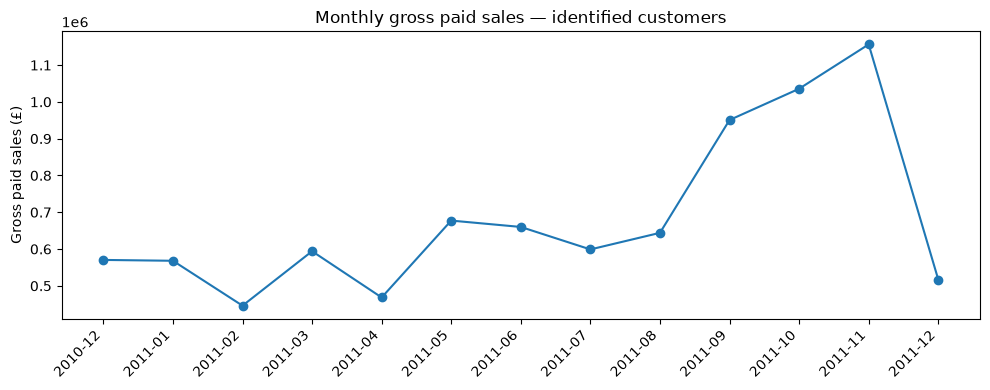

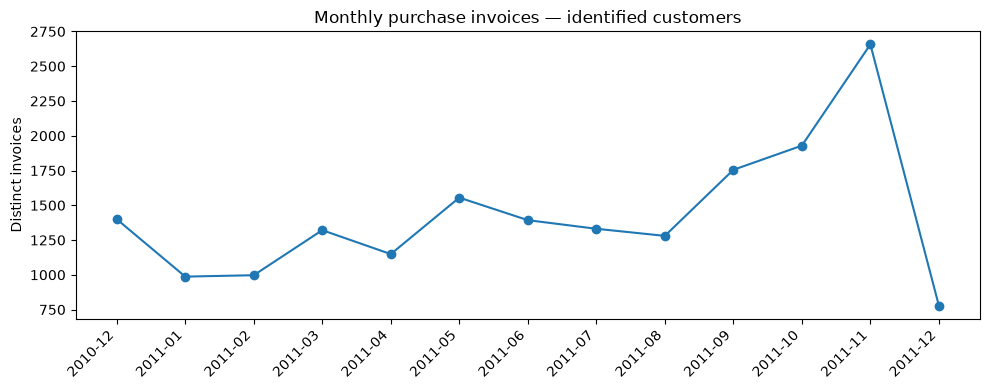

In [6]:
monthly = paid.groupby('Month').agg(
    GrossSales=('LineValue','sum'),
    InvoiceLines=('InvoiceNo','size'),
    DistinctInvoices=('InvoiceNo','nunique'),
    Customers=('CustomerID','nunique')
).reset_index()
display(monthly)
monthly.to_csv(TAB/'monthly_sales_transactions.csv', index=False)
plt.figure(figsize=(10,4)); plt.plot(monthly['Month'], monthly['GrossSales'], marker='o'); plt.xticks(rotation=45, ha='right'); plt.ylabel('Gross paid sales (£)'); plt.title('Monthly gross paid sales — identified customers'); plt.tight_layout(); plt.savefig(FIG/'monthly_sales.png', dpi=160); plt.show()
plt.figure(figsize=(10,4)); plt.plot(monthly['Month'], monthly['DistinctInvoices'], marker='o'); plt.xticks(rotation=45, ha='right'); plt.ylabel('Distinct invoices'); plt.title('Monthly purchase invoices — identified customers'); plt.tight_layout(); plt.savefig(FIG/'monthly_invoices.png', dpi=160); plt.show()

### EDA Findings: Monthly Sales and Purchase Activity

The monthly analysis indicates considerable variation in sales and purchasing activity throughout the observation period (December 2010–December 2011).

Gross paid sales remained relatively stable, fluctuating between approximately £446,085 and £677,355, from December 2010 through August 2011. A substantial increase was observed from September 2011 onwards, with sales reaching approximately £950,690 in September, £1,035,642 in October and a peak of £1,156,206 in November 2011.

The number of distinct purchase invoices followed a broadly similar pattern. November 2011 recorded the highest transaction activity, with 2,657 distinct invoices and 1,664 identified customers. This suggests that the increase in sales during the final quarter was accompanied by an increase in purchasing activity.

December 2011 recorded lower sales and invoice volumes. However, the dataset ends on 9 December 2011, making this an incomplete observation period. Consequently, December should not be directly compared with complete calendar months when interpreting monthly performance.

**Implications for customer segmentation:** The observed variation in purchasing activity supports the inclusion of transaction frequency and monetary expenditure as important customer-level segmentation variables. Temporal patterns also reinforce the importance of defining recency and purchase regularity carefully.

**Limitation:** These figures are descriptive aggregates and do not establish the reasons behind the increase in sales. Furthermore, the current paid-purchase view includes certain special transaction codes that will be addressed during the formal preprocessing stage.

## 3.2 Country distribution

Compare identified customer counts, distinct invoices and gross paid sales across countries. Country is retained primarily for post-clustering profiling rather than as a primary numerical clustering feature.

,Country,Customers,Invoices,GrossSales
0,United Kingdom,3920,16646,7285024.644
1,Netherlands,9,94,285446.340
2,EIRE,3,260,265262.460
3,Germany,94,457,228678.400
4,France,87,389,208934.310
5,Australia,9,57,138453.810
6,Spain,30,90,61558.560
7,Switzerland,21,51,56443.950
8,Belgium,25,98,41196.340
9,Sweden,8,36,38367.830


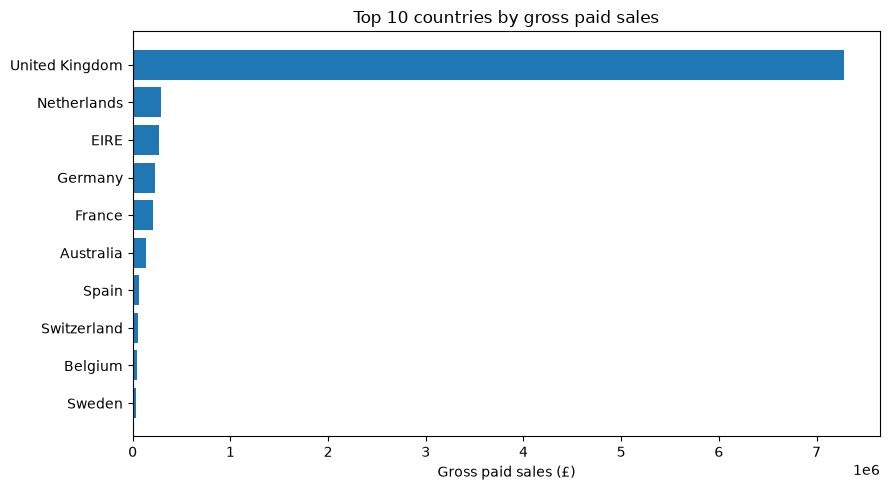

In [7]:
country = paid.groupby('Country').agg(Customers=('CustomerID','nunique'), Invoices=('InvoiceNo','nunique'), GrossSales=('LineValue','sum')).sort_values('GrossSales', ascending=False).reset_index()
display(country.head(15))
country.to_csv(TAB/'country_profile.csv', index=False)
top_country = country.head(10).sort_values('GrossSales')
plt.figure(figsize=(9,5)); plt.barh(top_country['Country'], top_country['GrossSales']); plt.xlabel('Gross paid sales (£)'); plt.title('Top 10 countries by gross paid sales'); plt.tight_layout(); plt.savefig(FIG/'country_sales_top10.png', dpi=160); plt.show()

### EDA Findings: Country-wise Sales and Customer Distribution

The country-wise analysis reveals a substantial concentration of customers and sales in the United Kingdom. Out of 4,338 identified customers in the paid-purchase view, 3,920 (approximately 90.36%) are from the United Kingdom. The country contributes approximately £7.29 million in gross paid sales, representing around 81.98% of total gross paid sales.

The Netherlands, EIRE, Germany and France are among the other significant markets by gross sales. Notably, the Netherlands generated approximately £285,446 from only nine identified customers, while EIRE generated approximately £265,262 from three customers and 260 distinct invoices. These observations suggest differences in transaction activity across international markets, although customer-level analysis is required before drawing conclusions about individual customer value.

Germany and France have comparatively larger international customer bases, with 94 and 87 identified customers respectively.

**Implications for customer segmentation:** Country should primarily be retained as a post-clustering profiling variable rather than included as a direct numerical clustering feature. This will allow the distribution of customer segments across geographical markets to be examined without allowing the strong UK concentration to dominate the clustering process.

**Limitation:** Several international markets have very small customer populations. Therefore, country-level comparisons should be interpreted cautiously. The current figures also come from the preliminary paid-purchase view, and special transaction codes will be addressed during formal preprocessing.

## 3.3 Product popularity

Identify products with the highest recorded unit volumes and compare quantities with gross sales. Product rankings are descriptive and may be affected by unusually large transactions and their associated cancellation records.

,StockCode,Description,Units,GrossSales
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,77916,81416.73
2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54319,13558.41
3,85099B,JUMBO BAG RED RETROSPOT,46078,85040.54
4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,36706,100392.10
5,84879,ASSORTED COLOUR BIRD ORNAMENT,35263,56413.03
6,21212,PACK OF 72 RETROSPOT CAKE CASES,33670,16381.88
7,22197,POPCORN HOLDER,30919,23417.51
8,23084,RABBIT NIGHT LIGHT,27153,51251.24
9,22492,MINI PAINT SET VINTAGE,26076,16039.24


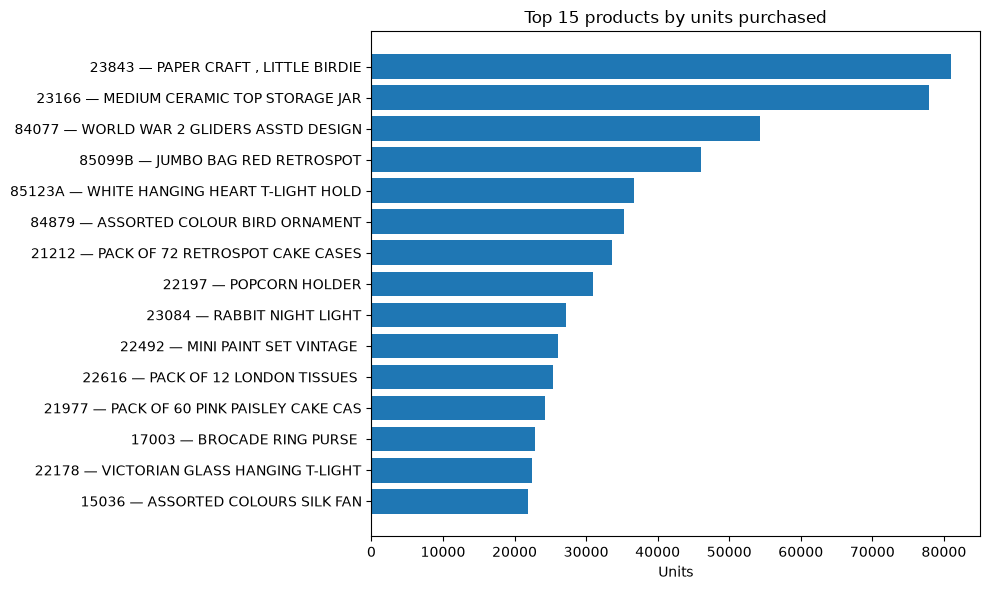

In [8]:
products = paid.groupby(['StockCode','Description'], dropna=False).agg(Units=('Quantity','sum'), GrossSales=('LineValue','sum')).sort_values('Units', ascending=False).reset_index()
display(products.head(15))
products.to_csv(TAB/'product_popularity.csv', index=False)
top_products = products.head(15).sort_values('Units')
labels = top_products['StockCode'].astype(str) + ' — ' + top_products['Description'].fillna('').astype(str).str.slice(0,32)
plt.figure(figsize=(10,6)); plt.barh(labels, top_products['Units']); plt.xlabel('Units'); plt.title('Top 15 products by units purchased'); plt.tight_layout(); plt.savefig(FIG/'top_products_quantity.png', dpi=160); plt.show()

### Interpretation: Product popularity

`PAPER CRAFT, LITTLE BIRDIE` has the highest recorded quantity in this preliminary view (80,995 units), followed by `MEDIUM CERAMIC TOP STORAGE JAR` (77,916 units). High unit volume does not necessarily correspond to the highest gross sales: product price differences matter.

The unusually high recorded quantities for some products connect to extreme transactions identified during data-quality assessment. The preliminary paid-purchase view excludes cancellation invoices but can retain the original positive purchase lines. Therefore, product-level quantities should be interpreted cautiously until the transaction-level preprocessing decisions are applied.

## 3.4 Quantity and unit-price distributions

Inspect positive transaction quantities and positive unit prices. The quantity histogram is visually capped at the 99th percentile, and unit prices are displayed on a logarithmic scale to make their right-skewed distributions easier to inspect. These are display transformations, not changes to the underlying data.

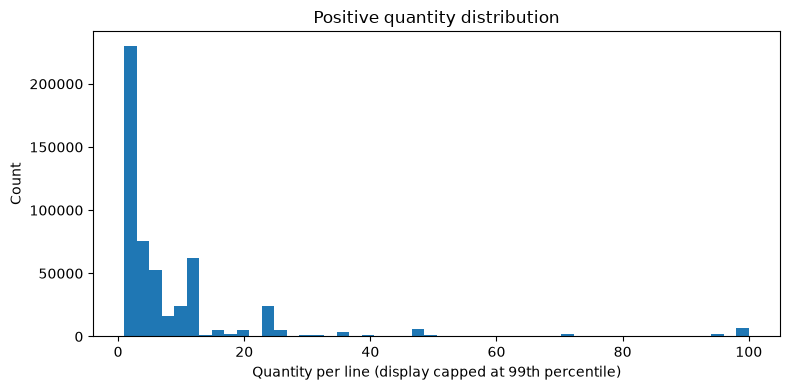

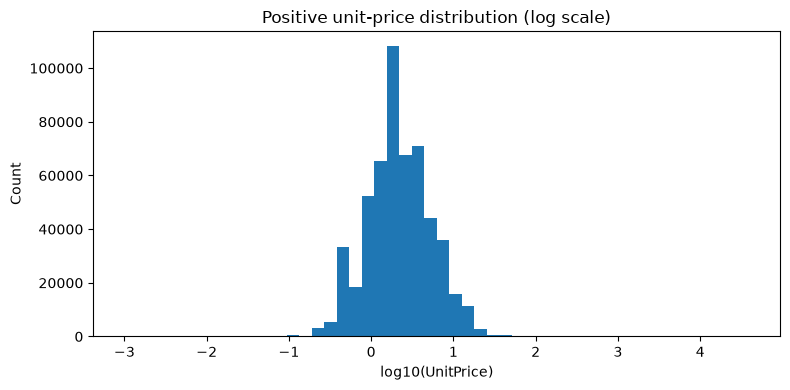

In [9]:
positive_q = df.loc[df['Quantity'] > 0, 'Quantity']
plt.figure(figsize=(8,4)); plt.hist(positive_q.clip(upper=positive_q.quantile(.99)), bins=50); plt.xlabel('Quantity per line (display capped at 99th percentile)'); plt.ylabel('Count'); plt.title('Positive quantity distribution'); plt.tight_layout(); plt.savefig(FIG/'quantity_distribution.png', dpi=160); plt.show()
positive_p = df.loc[df['UnitPrice'] > 0, 'UnitPrice']
plt.figure(figsize=(8,4)); plt.hist(np.log10(positive_p), bins=50); plt.xlabel('log10(UnitPrice)'); plt.ylabel('Count'); plt.title('Positive unit-price distribution (log scale)'); plt.tight_layout(); plt.savefig(FIG/'unit_price_distribution_log.png', dpi=160); plt.show()

### EDA Findings: Product Popularity and Transaction Distributions

The product-level analysis indicates considerable variation in purchasing quantities and gross sales across products. PAPER CRAFT LITTLE BIRDIE recorded the highest quantity, with 80,995 units, followed by MEDIUM CERAMIC TOP STORAGE JAR and WORLD WAR 2 GLIDERS ASSTD DESIGNS.

The comparison between quantities and gross sales demonstrates that products with high purchase volumes do not necessarily generate proportionately high sales values. For example, WORLD WAR 2 GLIDERS recorded 54,319 units but generated approximately £13,558 in gross sales. In contrast, WHITE HANGING HEART T-LIGHT HOLDER generated approximately £100,392 from 36,706 units. This highlights the importance of examining both purchasing volume and monetary expenditure.

The positive quantity distribution is highly right-skewed, with most transaction lines containing relatively small quantities and a limited number of observations involving exceptionally large quantities. The positive unit-price distribution also exhibits concentration at lower price levels, with a long upper tail. The logarithmic representation of unit prices makes the distribution easier to inspect.

The unusually high quantities observed for certain products are consistent with extreme transaction records identified during the data-quality assessment. In particular, some large purchase transactions have corresponding cancellation records in the original dataset. Since the preliminary paid-purchase view excludes cancellation invoices but retains positive purchase records, these transactions require further investigation during formal preprocessing.

**Implications for customer segmentation:** Quantity and Monetary are potentially informative customer-level features, but their distributions may be heavily influenced by extreme observations. Their distributions should be examined after customer-level aggregation, and appropriate transformations or robust scaling techniques should be considered. Genuine high-volume purchases should not be removed solely because they are statistical outliers.

**Limitation:** The product rankings describe recorded transaction quantities and gross sales, not necessarily net retained sales after cancellations. The positive quantity and unit-price histograms are based on the original dataset with positivity filters and should not be interpreted as distributions of the final merchandise-only analytical dataset.

## 3.5 Customer spending and purchase frequency

Aggregate the preliminary paid-purchase view to customer level and examine spending, distinct invoice frequency, total quantity and product diversity. These summaries are exploratory and will be recalculated using the final merchandise-only customer dataset in Notebook 04.

,count,mean,std,min,50%,90%,95%,99%,99.5%,99.9%,max
CustomerSpend,4338.0,2048.688081,8985.230220,3.75,668.57,3640.841,5789.9995,19780.4878,41003.7178,137376.70232,280206.02
PurchaseFrequency,4338.0,4.272015,7.697998,1.00,2.00,9.000,13.0000,30.0000,41.9450,92.32600,209.00
TotalQuantity,4338.0,1187.644537,5043.619654,1.00,378.00,2110.600,3570.9000,11016.2400,26390.8250,72785.44600,196915.00
ProductDiversity,4338.0,61.501153,85.366768,1.00,35.00,143.000,205.0000,354.0000,440.3150,862.09500,1787.00


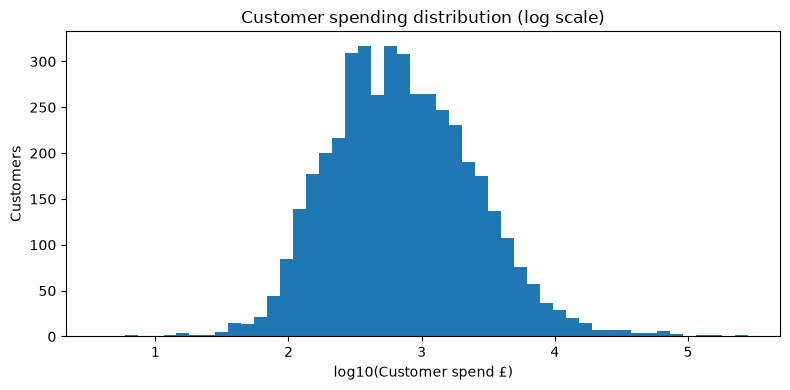

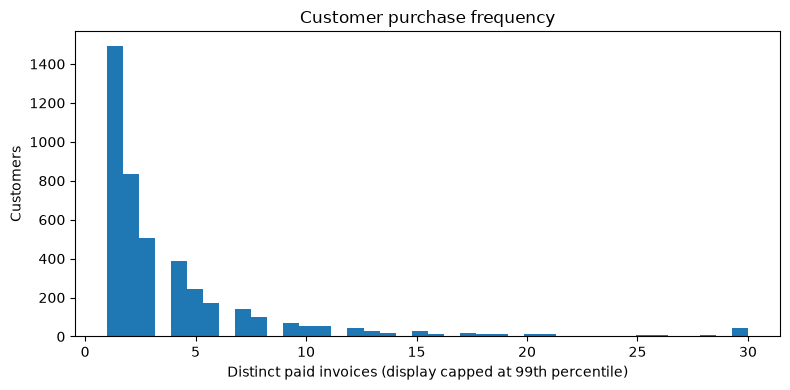

In [10]:
customer = paid.groupby('CustomerID').agg(
    CustomerSpend=('LineValue','sum'),
    PurchaseFrequency=('InvoiceNo','nunique'),
    TotalQuantity=('Quantity','sum'),
    ProductDiversity=('StockCode','nunique')
).reset_index()
display(customer[['CustomerSpend','PurchaseFrequency','TotalQuantity','ProductDiversity']].describe(percentiles=[.5,.9,.95,.99,.995,.999]).T)
customer.to_csv(TAB/'customer_descriptive_profile.csv', index=False)
plt.figure(figsize=(8,4)); plt.hist(np.log10(customer['CustomerSpend'].clip(lower=.01)), bins=50); plt.xlabel('log10(Customer spend £)'); plt.ylabel('Customers'); plt.title('Customer spending distribution (log scale)'); plt.tight_layout(); plt.savefig(FIG/'customer_spending_log.png', dpi=160); plt.show()
plt.figure(figsize=(8,4)); plt.hist(customer['PurchaseFrequency'].clip(upper=customer['PurchaseFrequency'].quantile(.99)), bins=40); plt.xlabel('Distinct paid invoices (display capped at 99th percentile)'); plt.ylabel('Customers'); plt.title('Customer purchase frequency'); plt.tight_layout(); plt.savefig(FIG/'customer_purchase_frequency.png', dpi=160); plt.show()

### Interpretation: Customer purchasing behaviour

The preliminary customer-level analysis covers **4,338 identified customers**. Spending is strongly right-skewed: mean spending is approximately **£2,048.69**, compared with a median of **£668.57**. The maximum is **£280,206.02**.

Purchase frequency is also skewed. The median customer has **2 distinct invoices**, while the mean is approximately **4.27** and the maximum is **209**. Total quantity has a median of **378 units** and a mean of approximately **1,187.64**. Product diversity has a median of **35 distinct products**.

The large differences between means and medians indicate substantial heterogeneity and a small number of high-value or high-volume customers. This supports examining transformations and scaling during preprocessing, while investigating extreme observations rather than automatically deleting them.

**Limitation:** These are preliminary paid-purchase statistics that include special transaction codes. Final customer features and descriptive statistics are recalculated after formal preprocessing.

## 3.6 Cancellation activity — separate descriptive view

Examine C-prefixed cancellation records separately from completed purchase activity. Cancellation values are shown as absolute line values for descriptive investigation only; they are not treated as confirmed revenue reversals because original purchase matches are not reliably established.

,Month,CancellationLines,DistinctCancellationInvoices,AbsoluteLineValue
0,2010-12,728,326,74789.12
1,2011-01,701,260,131364.30
2,2011-02,475,219,25569.24
3,2011-03,699,318,34372.28
4,2011-04,559,240,44601.50
5,2011-05,621,314,47202.51
6,2011-06,711,329,70616.78
7,2011-07,685,270,37921.08
8,2011-08,668,278,54333.75
9,2011-09,805,333,38902.55


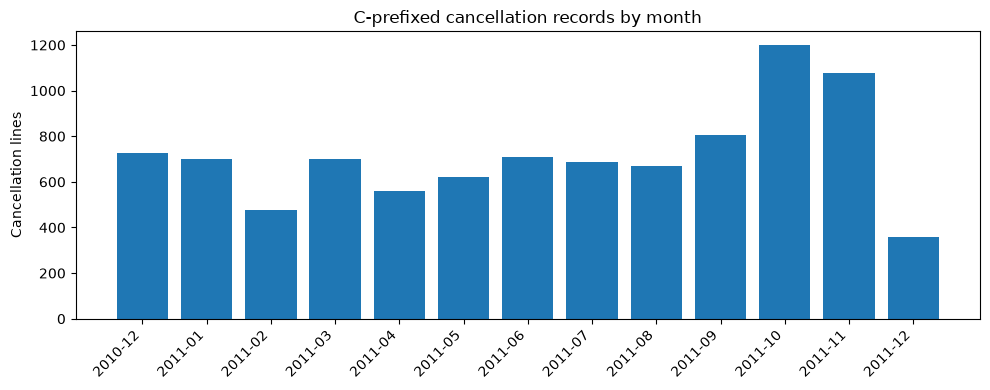

In [11]:
invoice_text = df['InvoiceNo'].astype('string')
is_cancel = invoice_text.str.startswith('C', na=False)
cancel = df.loc[is_cancel].copy()
cancel['Month'] = cancel['InvoiceDate'].dt.to_period('M').astype(str)
cancel['AbsLineValue'] = (cancel['Quantity'] * cancel['UnitPrice']).abs()
cancel_monthly = cancel.groupby('Month').agg(CancellationLines=('InvoiceNo','size'), DistinctCancellationInvoices=('InvoiceNo','nunique'), AbsoluteLineValue=('AbsLineValue','sum')).reset_index()
display(cancel_monthly)
cancel_monthly.to_csv(TAB/'cancellations_by_month.csv', index=False)
plt.figure(figsize=(10,4)); plt.bar(cancel_monthly['Month'], cancel_monthly['CancellationLines']); plt.xticks(rotation=45, ha='right'); plt.ylabel('Cancellation lines'); plt.title('C-prefixed cancellation records by month'); plt.tight_layout(); plt.savefig(FIG/'cancellations_by_month.png', dpi=160); plt.show()

### Interpretation: Cancellation activity

Cancellation activity varies across the observation period. October 2011 has the highest number of cancellation lines (**1,200**), while November 2011 has the highest number of distinct cancellation invoices (**441**).

December 2011 records an absolute cancellation line value of approximately **£205,124.67**, despite containing 360 cancellation lines. The month is incomplete, and the large absolute value warrants investigation rather than direct interpretation as a confirmed reversal.

**Preprocessing implication:** Keep cancellation records separate from the primary completed-purchase calculations unless a reliable transaction-level match is established. Do not subtract unmatched cancellation values from customer expenditure.

## 4. Consolidated EDA findings and preprocessing implications

The following checklist summarises what the exploratory analyses show and how each finding informs subsequent preprocessing.

## 3.7 EDA interpretation checklist


The exploratory data analysis produced the following observations and preprocessing implications.

| Analysis | What is shown | Strongest pattern | Caveat | Implication for preprocessing |
|---|---|---|---|---|
| Monthly sales | Monthly gross paid sales across the observation period | Sales increased substantially from September to November 2011, peaking in November | December 2011 is incomplete, as data ends on 9 December | Retain transaction dates and account for the incomplete final month |
| Monthly invoices | Number of distinct purchase invoices per month | Invoice activity increased considerably towards the end of 2011, peaking in November | Monthly invoice counts reflect the preliminary paid-purchase filter | Use distinct invoices to construct customer purchase frequency |
| Country distribution | Customers, invoices and gross sales across countries | United Kingdom dominates customer numbers and sales | Several international markets have very small customer populations | Retain Country for post-clustering profiling rather than primary clustering |
| Product popularity | Products ranked by total units purchased | A few products account for exceptionally high recorded quantities | Some high-volume purchase records have corresponding cancellation records | Investigate unusual transactions before calculating customer-level quantity |
| Quantity distribution | Distribution of positive transaction quantities | Highly right-skewed, with a long upper tail | Extreme quantities may influence aggregate customer purchasing behaviour | Investigate outliers and consider appropriate transformations |
| Unit-price distribution | Distribution of positive unit prices using a logarithmic scale | Most transaction lines are concentrated at lower unit prices, with a long upper tail | Special transaction codes and unusually priced records may influence the distribution | Examine monetary features and consider log transformation or robust scaling |
| Customer spending | Distribution and summary statistics of customer expenditure | Mean spending substantially exceeds median spending, indicating right skewness | Based on the preliminary paid-purchase view, including special transaction codes | Investigate extreme customer expenditure and recalculate after formal preprocessing |
| Purchase frequency | Distribution of distinct paid invoices per customer | Most customers have relatively few invoices, while a small group purchases frequently | Frequency is based on the preliminary paid-purchase view | Retain distinct invoice count as an important segmentation feature |
| Total quantity | Total units purchased by each customer | Mean quantity is substantially higher than median quantity | Extreme transactions and candidate cancellation relationships may influence totals | Recalculate after transaction-level cleaning and investigate high-volume customers |
| Product diversity | Number of distinct products purchased by each customer | Considerable variation exists in customers' product assortment | Special StockCodes should not be treated as merchandise products | Calculate diversity using genuine merchandise StockCodes |
| Cancellation activity | Monthly cancellation lines, invoices and absolute line values | Cancellation activity varies across months, with high line counts in October and invoice counts in November | Cancellation records cannot be reliably matched to original purchases; December has an unusually high absolute value despite being incomplete | Retain cancellations separately and avoid subtracting uncertain cancellation values |

**Overall EDA conclusions**

1. Customer purchasing behaviour is heterogeneous, with substantial variation in spending, purchase frequency, quantity and product diversity.
2. Several transaction-level and customer-level variables exhibit right-skewed distributions and extreme observations.
3. The dataset is geographically concentrated in the United Kingdom, making country more appropriate for post-clustering profiling.
4. Cancellation records require separate treatment because reliable transaction-level reversal matching has not been established.
5. Genuine alphanumeric StockCodes represent valid merchandise identifiers and should not be removed indiscriminately.
6. Special transaction codes such as POST, DOT and M require separate treatment when constructing merchandise-based features.
7. The final customer-level analytical dataset must be created only after implementing the documented data-quality and preprocessing decisions.

**Limitations:** The EDA is descriptive and does not establish causal relationships. Several findings are based on the preliminary paid-purchase view rather than the final merchandise-only dataset. All final customer-level statistics must therefore be recalculated after preprocessing.

## 5. Notebook summary

### Work completed
- Loaded the original 541,909-row dataset and constructed a preliminary customer-identified paid-purchase view.
- Investigated StockCode patterns, distinguishing valid alphanumeric merchandise identifiers from special transaction codes.
- Examined monthly sales and invoice activity, country distribution and product popularity.
- Inspected transaction-level quantity and unit-price distributions.
- Examined customer-level spending, purchase frequency, total quantity and product diversity.
- Analysed cancellation activity separately.

### Main findings
- Purchasing activity is concentrated in the United Kingdom, although several international markets contribute meaningful sales.
- Monthly sales and invoice activity increased substantially in September–November 2011; December is incomplete.
- Customer spending, purchase frequency and quantities are strongly right-skewed.
- Valid alphanumeric StockCodes must be retained; special codes require targeted treatment.
- Cancellation records cannot generally be treated as confirmed reversals without reliable matching.

### Decisions carried forward
- Use Country for post-clustering profiling, not as a primary clustering input.
- Exclude `POST`, `DOT` and `M` from primary merchandise-based features.
- Investigate extreme observations rather than removing them solely because they are large.
- Keep cancellation records separate from completed-purchase calculations unless a reliable match is established.
- Recalculate customer-level statistics after formal preprocessing.

### Transition to Notebook 04
Notebook 04 implements the documented transaction-level cleaning rules, constructs customer-level RFM and extended behavioural features, and prepares the scaled datasets used for clustering.

**Scope reminder:** This notebook is descriptive. Its preliminary paid-purchase statistics should not be substituted for the final merchandise-only modelling results.